# Captum tour: feature attribution

The data and the two models are described in `01_data_and_models`.

In [1]:
from toy import *  # shared setup: data, the two models (trained once, then cached), helpers

**Question**: which input features does a model use?

```python
attr = Method(wide).attribute(x, target=y)     # x: (N, 16)  →  attr: (N, 16)
attr[i, j]    # how much feature j pushed example i's score for its true class y[i]
```

Each figure has one row per method:

* **left**: `attr` for one example, signed (blue pushes the score up, red pushes it down)
* **right**: `mean(|attr|)` over 256 probe examples, as a share, with the ground truth as black ticks

§4–§10 use the wide model. §11 compares narrow and wide.

In [2]:
with torch.no_grad():
    both_right = (NARROW(PX).argmax(-1) == PY) & (WIDE(PX).argmax(-1) == PY)
EX = int(both_right.nonzero()[0])  # the example shown in the "one example" panels
FEATURE_METHODS = {}  # every Part 3 method: name -> (explain(x, target), output units, number of examples)


def run_family(methods, n=None):
    """methods = {name: (explain(x, target), units)}; units: 'score', 'grad' or None. Returns attributions."""
    out = {}
    for name, (explain, units) in methods.items():
        FEATURE_METHODS[name] = (explain, units, n)
        x, y = (PX, PY) if n is None else (PX[:n], PY[:n])
        out[name] = explain(x, target=y).detach()
    return out


def plot_feature_methods(attrs, title):
    names = list(attrs)
    fig, axes = plt.subplots(len(names) + 1, 2, figsize=(11.5, 0.95 * len(names) + 2.3),
                             gridspec_kw=dict(height_ratios=[1.25] + [1] * len(names)))
    axes[0, 0].bar(range(N_FEATURES), PX[EX].numpy(), color=NEUTRAL, width=0.7)
    axes[0, 0].axhline(0, color=INK2, lw=0.8)
    axes[0, 0].set_title(f"Example #{EX} (true class {int(PY[EX])}): input values", loc="left")
    axes[0, 1].bar(range(N_FEATURES), TRUTH_SHARE.numpy(), color=NEUTRAL, width=0.7)
    axes[0, 1].set_title("Ground truth: share of importance", loc="left")
    for i, name in enumerate(names, start=1):
        local = attrs[name][EX].numpy()
        ax = axes[i, 0]
        ax.bar(range(N_FEATURES), local, color=[POS if v >= 0 else NEG for v in local], width=0.7)
        ax.axhline(0, color=INK2, lw=0.8)
        lim = np.abs(local).max() * 1.15 + 1e-12
        ax.set_ylim(-lim, lim)
        ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=9.5, color=INK)
        ax = axes[i, 1]
        ax.bar(range(N_FEATURES), share(attrs[name]).numpy(), color=POS, width=0.7)
        ax.hlines(TRUTH_SHARE.numpy(), np.arange(N_FEATURES) - 0.38, np.arange(N_FEATURES) + 0.38,
                  color=INK, lw=1.5, label="ground truth")
        ax.set_ylim(0, 0.3)
    for i, row in enumerate(axes):
        for ax in row:
            feature_axis(ax, ticklabels=(i == len(names)), group_labels=(i == 0))
            ax.set_yticks([])
            ax.spines["left"].set_visible(False)
    axes[1, 0].set_title("this example (blue +, red −)", loc="left", fontsize=9, color=INK2, weight="normal")
    axes[1, 1].set_title("all examples: mean |attribution|, share", loc="left", fontsize=9, color=INK2,
                         weight="normal")
    axes[1, 1].legend(loc="upper right", fontsize=8.5)
    fig.suptitle(title, fontweight="bold", color=INK)
    plt.show()

## 4. Gradient methods

```python
g = d scores[y] / d x                    # (N, 16): slope of the true-class score per feature

Saliency(model)        → g               # abs=False keeps the sign
InputXGradient(model)  → g * x
GuidedBackprop(model)  → g, but each ReLU passes back only positive gradients
Deconvolution(model)   → g, but each ReLU passes back relu(gradient), ignoring the forward pass
```

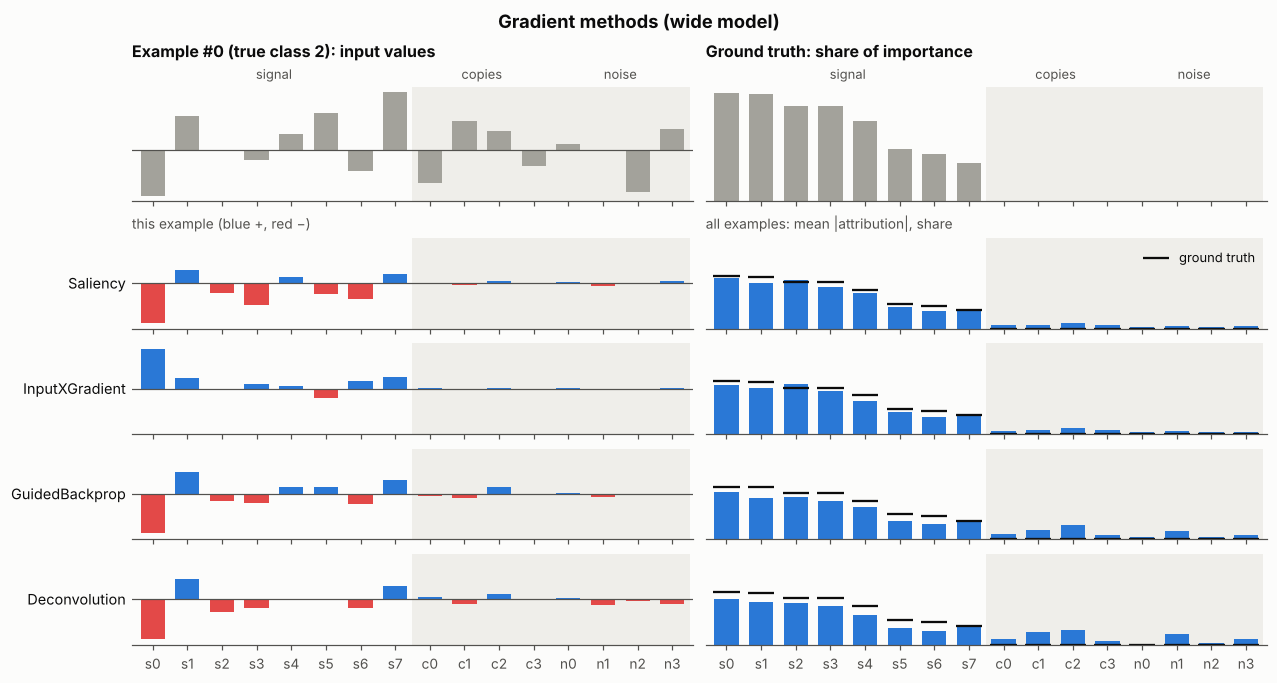

spread between examples of the same class: {'Saliency': np.float64(0.528), 'InputXGradient': np.float64(0.971), 'GuidedBackprop': np.float64(0.37), 'Deconvolution': np.float64(0.0)}


In [3]:
attrs_grad = run_family({
    "Saliency": (lambda x, target: Saliency(WIDE).attribute(x, target=target, abs=False), "grad"),
    "InputXGradient": (lambda x, target: InputXGradient(WIDE).attribute(x, target=target), "score"),
    "GuidedBackprop": (lambda x, target: GuidedBackprop(WIDE).attribute(x, target=target), "grad"),
    "Deconvolution": (lambda x, target: Deconvolution(WIDE).attribute(x, target=target), "grad"),
})
plot_feature_methods(attrs_grad, "Gradient methods (wide model)")


def same_class_spread(a):
    """How much attributions differ between examples of the same class (0 = identical)."""
    return np.mean([(a[PY == c].std(0).sum() / a[PY == c].abs().mean(0).sum()).item() for c in range(N_CLASSES)])


print("spread between examples of the same class:",
      {k: round(same_class_spread(v), 3) for k, v in attrs_grad.items()})

* All four rank the signals roughly in ground-truth order and give copies and noise little weight.
* InputXGradient = Saliency × input value, so the sign flips wherever the input is negative (`s0` here).
* `Deconvolution` gives every example of a class exactly the same attribution (spread 0): in a ReLU network its
  backward pass does not depend on the input at all.

## 5. Reference-based methods

These compare `x` with a **baseline** ("feature absent"). Here the baseline is all zeros, the feature means.

```python
IntegratedGradients → (x - baseline) * mean of g at 32 points on the line from baseline to x
DeepLift            → same goal in one backward pass, using differences from the baseline at each ReLU
DeepLiftShap        → mean of DeepLift over 16 baselines (real examples)
GradientShap        → IntegratedGradients with a random baseline and a random point on the line, averaged
LRP                 → pass the score backwards layer by layer, split in proportion to each input's share

completeness:  attr[i].sum() ≈ score(x[i]) - score(baseline)
```

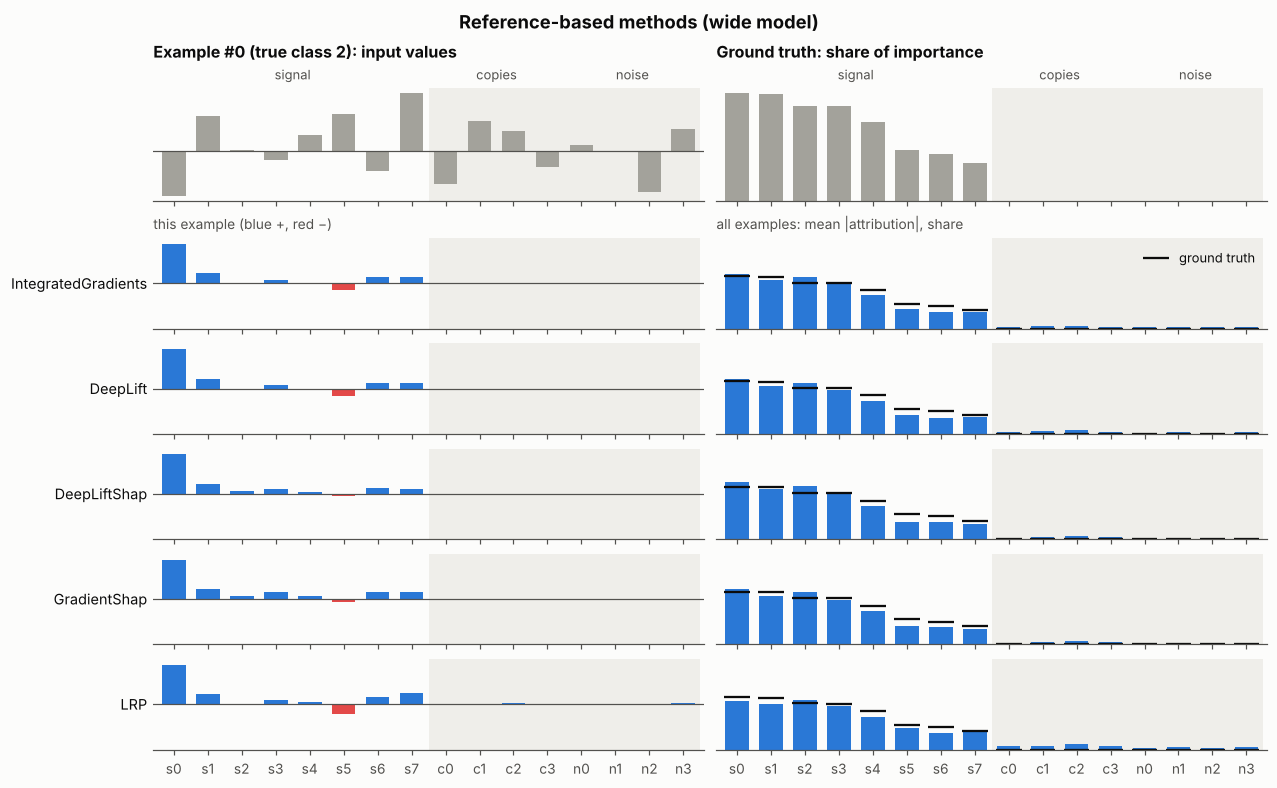

In [4]:
torch.manual_seed(0)
attrs_ref = run_family({
    "IntegratedGradients": (lambda x, target: IntegratedGradients(WIDE).attribute(x, target=target, n_steps=32), "score"),
    "DeepLift": (lambda x, target: DeepLift(WIDE).attribute(x, target=target), "score"),
    "DeepLiftShap": (lambda x, target: DeepLiftShap(WIDE).attribute(x, baselines=DIST, target=target), "score"),
    "GradientShap": (lambda x, target: GradientShap(WIDE).attribute(x, baselines=DIST, target=target, n_samples=20), "score"),
    "LRP": (lambda x, target: LRP(WIDE).attribute(x, target=target), "score"),
})
plot_feature_methods(attrs_ref, "Reference-based methods (wide model)")

**Completeness**: the attributions should add up to `score(input) − score(baseline)`.
`return_convergence_delta=True` reports the gap for IntegratedGradients; it shrinks as `n_steps` grows.

In [5]:
with torch.no_grad():
    s_x = WIDE(PX).gather(1, PY[:, None]).squeeze(1)
    s_zero = WIDE(torch.zeros_like(PX)).gather(1, PY[:, None]).squeeze(1)
    s_dist = WIDE(DIST).mean(0)[PY]
targets = {"IntegratedGradients": s_x - s_zero, "DeepLift": s_x - s_zero, "DeepLiftShap": s_x - s_dist,
           "GradientShap": s_x - s_dist, "LRP": s_x}
display(pd.DataFrame({
    k: {"compared with": "score(x)" if k == "LRP" else "score(x) − score(baseline)",
        "relative gap": ((attrs_ref[k].sum(1) - t).abs().mean() / t.abs().mean()).item()}
    for k, t in targets.items()}).T)
for n_steps in [4, 16, 64]:
    _, delta = IntegratedGradients(WIDE).attribute(PX, target=PY, n_steps=n_steps, return_convergence_delta=True)
    print(f"IntegratedGradients n_steps={n_steps:>2}: median |convergence_delta| / |score gap| = "
          f"{(delta.abs() / (s_x - s_zero).abs()).median().item():.3f}")
print("max |LRP − InputXGradient| =", f"{(attrs_ref['LRP'] - attrs_grad['InputXGradient']).abs().max().item():.1e}")

,compared with,relative gap
IntegratedGradients,score(x) − score(baseline),0.004
DeepLift,score(x) − score(baseline),0.0
DeepLiftShap,score(x) − score(baseline),0.0
GradientShap,score(x) − score(baseline),0.118
LRP,score(x),0.216


IntegratedGradients n_steps= 4: median |convergence_delta| / |score gap| = 0.023
IntegratedGradients n_steps=16: median |convergence_delta| / |score gap| = 0.006
IntegratedGradients n_steps=64: median |convergence_delta| / |score gap| = 0.002
max |LRP − InputXGradient| = 1.5e-05


* All five match the ground-truth ranking closely.
* IntegratedGradients, DeepLift and DeepLiftShap add up almost exactly. GradientShap only does on average (13% gap
  here), because it samples random baselines and random points on the path.
* `LRP` is not complete here (biases absorb part of the score) and equals `InputXGradient` exactly: with Captum's
  default rules, LRP on a plain ReLU network reduces to gradient × input.

## 6. Perturbation methods

No gradients: change the input, rerun the model, record how much the score drops.

```python
for j in range(16):
    FeatureAblation[:, j]    = score(x) - score(x with column j set to 0)
    FeaturePermutation[:, j] = score(x) - score(x with column j shuffled across examples)

Occlusion: like FeatureAblation, but sets a window of 2 neighbouring columns to 0
           (made for images and sequences)
```

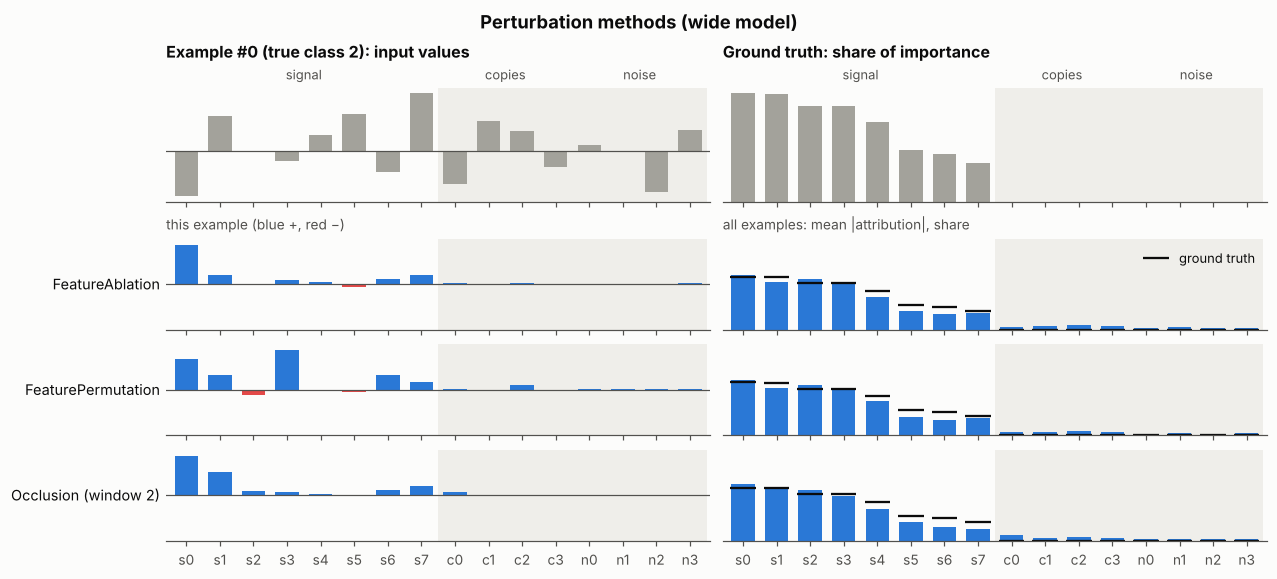

In [6]:
torch.manual_seed(0)
attrs_pert = run_family({
    "FeatureAblation": (lambda x, target: FeatureAblation(WIDE).attribute(x, baselines=0.0, target=target), "score"),
    "FeaturePermutation": (lambda x, target: FeaturePermutation(WIDE).attribute(x, target=target), "score"),
    "Occlusion (window 2)": (lambda x, target: Occlusion(WIDE).attribute(
        x, sliding_window_shapes=(2,), strides=1, baselines=0.0, target=target), "score"),
})
plot_feature_methods(attrs_pert, "Perturbation methods (wide model)")

* Over all examples, FeatureAblation and FeaturePermutation agree with the gradient-based methods. For a single
  example FeaturePermutation is erratic: the result depends on which value the shuffle happened to swap in.
* Occlusion blurs neighbours together: each window covers two adjacent features, so `c0` picks up some of the credit
  of `s7`, its neighbour.

## 7. Shapley values and local surrogate models

```python
ShapleyValueSampling[:, j] = average over 25 random orders of adding features:
                             score(features added before j, plus j) - score(features added before j)
ShapleyValues              = the exact version, over all subsets. Only feasible for a few features, so
                             feature_mask groups the 16 into 4: s0-s3, s4-s7, copies, noise

Lime:        masks z = 200 random on/off patterns over the features
             fit a small linear model  score(x, features off where z = 0) ≈ w · z;   attr = w
KernelShap:  Lime with weights on the masks that turn w into Shapley values
```

Lime and KernelShap fit a model per example, so they run on 32 examples.

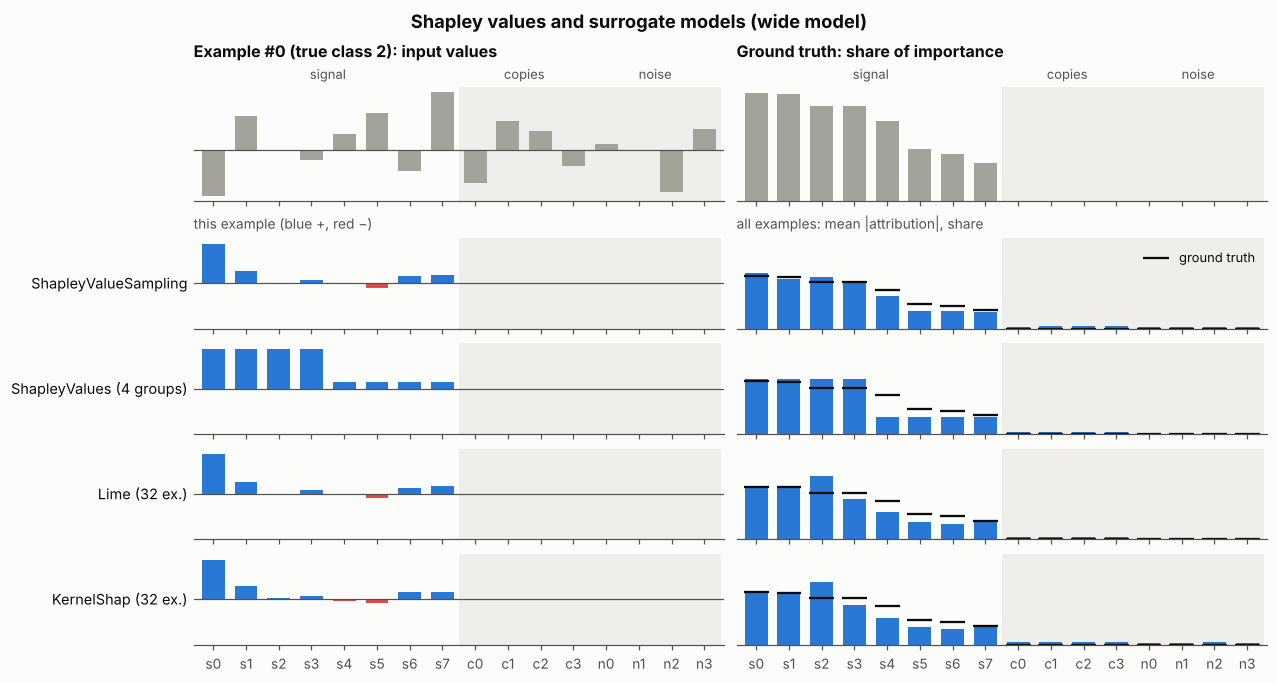

exact Shapley value per group, mean |value|: {'s0-s3': np.float32(25.0), 's4-s7': np.float32(7.9), 'copies': np.float32(0.84), 'noise': np.float32(0.55)}


In [7]:
GROUP_MASK = torch.tensor([[0] * 4 + [1] * 4 + [2] * 4 + [3] * 4])
torch.manual_seed(0)
attrs_shap = run_family({
    "ShapleyValueSampling": (lambda x, target: ShapleyValueSampling(WIDE).attribute(
        x, baselines=0.0, target=target, n_samples=25), "score"),
    "ShapleyValues (4 groups)": (lambda x, target: ShapleyValues(WIDE).attribute(
        x, baselines=0.0, target=target, feature_mask=GROUP_MASK), None),
})
attrs_shap.update(run_family({
    "Lime (32 ex.)": (lambda x, target: Lime(WIDE).attribute(x, baselines=0.0, target=target, n_samples=200), "score"),
    "KernelShap (32 ex.)": (lambda x, target: KernelShap(WIDE).attribute(
        x, baselines=0.0, target=target, n_samples=200), "score"),
}, n=32))
plot_feature_methods(attrs_shap, "Shapley values and surrogate models (wide model)")
group_values = attrs_shap["ShapleyValues (4 groups)"][:, [0, 4, 8, 12]]
print("exact Shapley value per group, mean |value|:",
      dict(zip(["s0-s3", "s4-s7", "copies", "noise"], group_values.abs().mean(0).numpy().round(2))))

* Sampled Shapley values match the ground truth as well as Integrated Gradients does.
* The exact group Shapley values put almost all credit on the two signal groups.
* Lime and KernelShap are noisier: each example's 200 random on/off samples are a small budget for 16 features.

## 8. `NoiseTunnel`: smoothing any method

```python
runs = [Saliency(wide).attribute(x + noise_k, target=y) for k in range(25)]    # noise sd 0.3
smoothgrad    = mean(runs)
smoothgrad_sq = mean(runs ** 2)
vargrad       = var(runs)
```

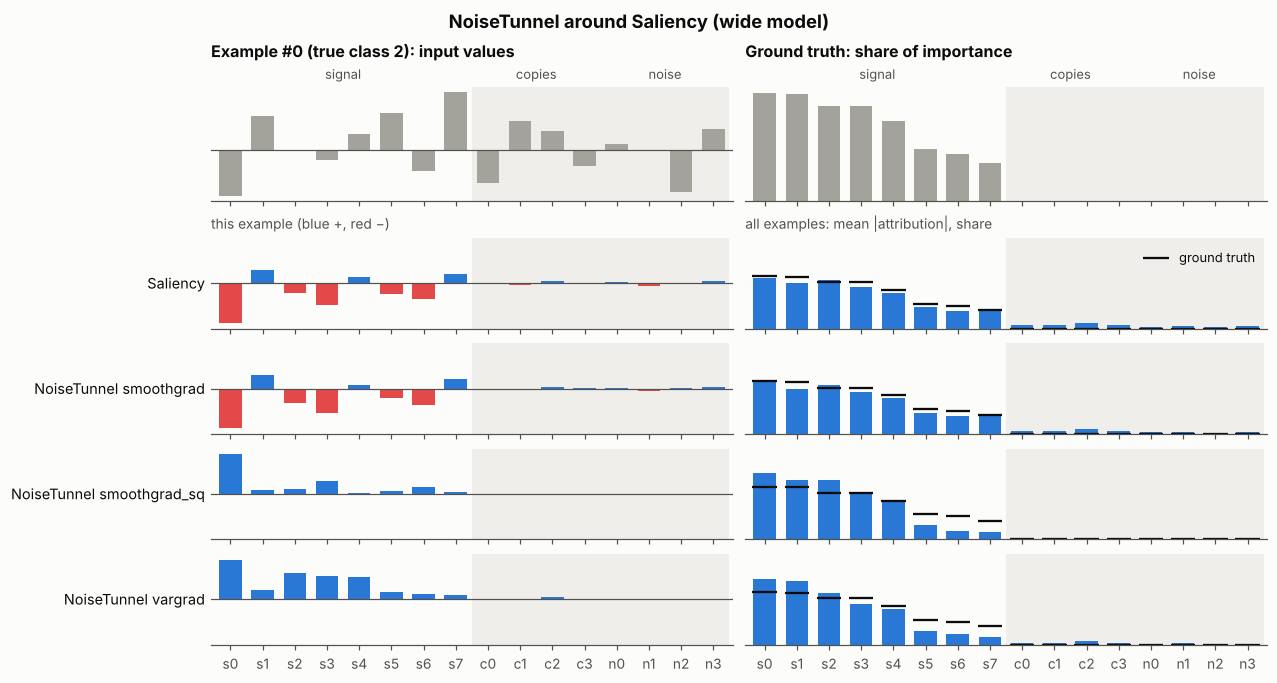

In [8]:
torch.manual_seed(0)
nt = NoiseTunnel(Saliency(WIDE))
attrs_nt = {"Saliency": attrs_grad["Saliency"]}
attrs_nt.update(run_family({
    f"NoiseTunnel {kind}": (lambda x, target, kind=kind: nt.attribute(
        x, nt_type=kind, nt_samples=25, stdevs=0.3, target=target, abs=False), "grad" if kind == "smoothgrad" else None)
    for kind in ["smoothgrad", "smoothgrad_sq", "vargrad"]
}))
plot_feature_methods(attrs_nt, "NoiseTunnel around Saliency (wide model)")

* `smoothgrad` keeps the sign and is close to plain Saliency: this model's gradients are already smooth.
* `smoothgrad_sq` and `vargrad` are always positive. They measure how strong or how variable the gradient is
  around the input, not which way it pushes.

## 9. Summaries over many examples: `ClassSummarizer` and `DataLoaderAttribution`

```python
summary = ClassSummarizer(CommonStats())        # running mean / var / min / max, kept per class
for x, y in loader:
    summary.update(IntegratedGradients(wide).attribute(x, target=y), y)
summary.class_summaries[c]["mean"]              # (16,): mean attribution for class c   → heatmap row

# DataLoaderAttribution(FeatureAblation(model)): one number per feature for the whole dataset
for j in range(16):
    drop[j] = accuracy(all data) - accuracy(all data with column j set to 0)     → bar chart
```

accuracy lost when s0 is removed: {'teacher (ceiling)': 0.345, 'wide': 0.318}


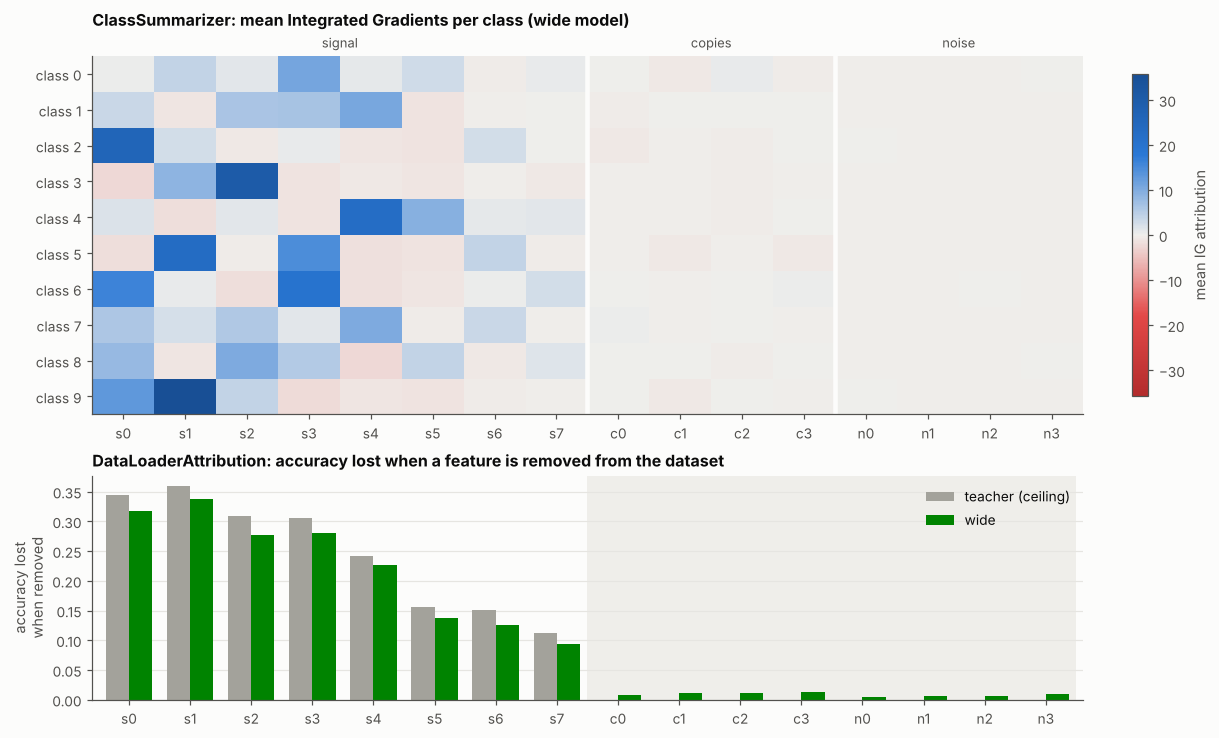

In [9]:
summary = ClassSummarizer(CommonStats())
ig = IntegratedGradients(WIDE)
for xb, yb in DataLoader(TensorDataset(X[:4000], Y[:4000]), batch_size=500):
    summary.update(ig.attribute(xb, target=yb, n_steps=16).detach(), yb.tolist())  # labels as plain ints
class_mean = torch.stack([summary.class_summaries[c][0]["mean"] for c in range(N_CLASSES)])



drop = {"teacher (ceiling)": accuracy_drop(teacher), "wide": accuracy_drop(WIDE)}
print("accuracy lost when s0 is removed:", {k: round(v[0].item(), 3) for k, v in drop.items()})

fig, axes = plt.subplots(2, 1, figsize=(11, 6.6), gridspec_kw=dict(height_ratios=[1.6, 1]))
ax = axes[0]
lim = class_mean.abs().max().item()
im = feature_heatmap(ax, class_mean.numpy(), [f"class {c}" for c in range(N_CLASSES)], cmap=DIVERGING, vmin=-lim, vmax=lim)
fig.colorbar(im, ax=ax, shrink=0.9, label="mean IG attribution")
ax.set_title("ClassSummarizer: mean Integrated Gradients per class (wide model)", loc="left")
ax = axes[1]
for k, (name, v) in enumerate(drop.items()):
    ax.bar(np.arange(N_FEATURES) + (k - 0.5) * 0.38, v.numpy(), width=0.38, label=name,
           color=NEUTRAL if name.startswith("teacher") else MODEL_COLOR["wide"])
feature_axis(ax)
ax.set_ylabel("accuracy lost\nwhen removed")
ax.set_title("DataLoaderAttribution: accuracy lost when a feature is removed from the dataset", loc="left")
ax.legend(loc="upper right")
plt.show()

* Each class relies on its own signed mix of signals; copies and noise are near zero for every class.
* Removing `s0` costs the wide model 32 accuracy points. The teacher's 34 points are the most any model
  could lose from it.

## 10. All feature methods side by side, and which to trust (`captum.metrics`)

```python
infidelity:   mask = a random 25% of the features
              error = (attr[mask].sum() - (score(x) - score(x with mask set to 0))) ** 2
              lower = attributions predict real removals better ("more faithful")

sensitivity:  x2 = x + noise of at most ±0.1
              change = max |attr(x2) - attr(x)| / |attr(x)|
              lower = the explanation is more stable
```

Both on 64 examples (Lime and KernelShap: infidelity only, on their 32). Squared and grouped outputs get no infidelity.

metrics in 2s


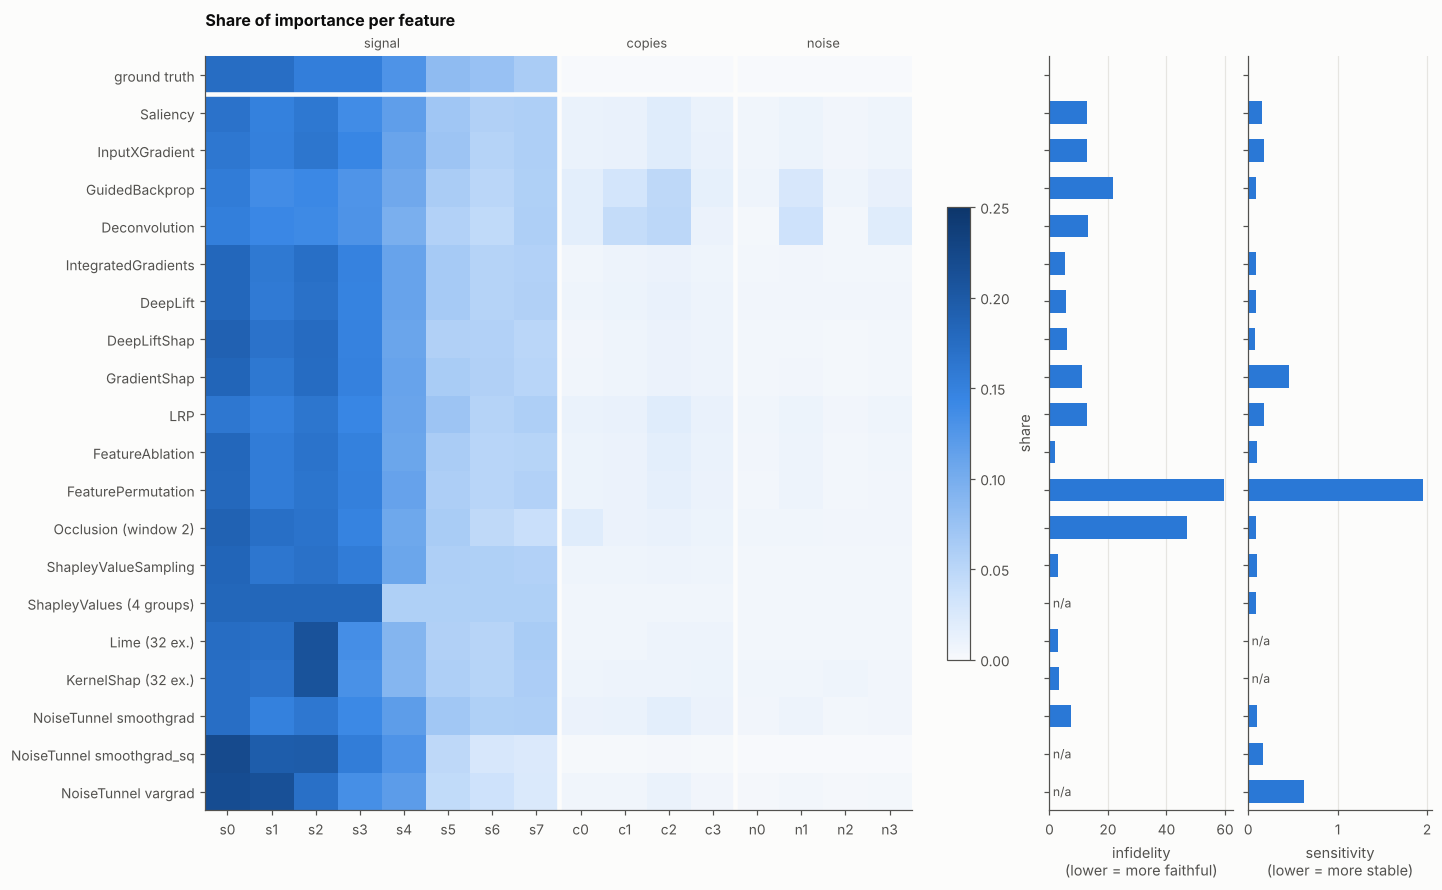

,infidelity,sensitivity
method,,
FeatureAblation,1.967,0.094
ShapleyValueSampling,2.844,0.102
Lime (32 ex.),2.907,NaN
KernelShap (32 ex.),3.333,NaN
IntegratedGradients,5.196,0.089
DeepLift,5.792,0.088
DeepLiftShap,6.066,0.074
NoiseTunnel smoothgrad,7.349,0.101
GradientShap,11.047,0.457


In [10]:
ALL = {**attrs_grad, **attrs_ref, **attrs_pert, **attrs_shap, **attrs_nt}


@infidelity_perturb_func_decorator(multiply_by_inputs=True)
def remove_random_features(inputs):
    return inputs * (torch.rand_like(inputs) > 0.25).float()


@infidelity_perturb_func_decorator(multiply_by_inputs=False)
def remove_random_features_grad(inputs):  # same, for gradient-type outputs (not in score units)
    return inputs * (torch.rand_like(inputs) > 0.25).float()


t0 = time.time()
rows = []
for name, (explain, units, n) in FEATURE_METHODS.items():
    k = min(64, n or 64)
    x, y, attr = PX[:k], PY[:k], ALL[name][:k]
    torch.manual_seed(0)
    inf = np.nan
    if units is not None:
        perturb = remove_random_features if units == "score" else remove_random_features_grad
        inf = infidelity(WIDE, perturb, x, attr, target=y, n_perturb_samples=20, normalize=True).mean().item()
    sens = np.nan if n else sensitivity_max(explain, x, target=y, perturb_radius=0.1, n_perturb_samples=5).mean().item()
    rows.append(dict(method=name, infidelity=inf, sensitivity=sens))
metrics = pd.DataFrame(rows).set_index("method")
print(f"metrics in {time.time() - t0:.0f}s")

names = list(FEATURE_METHODS)
fig, axes = plt.subplots(1, 3, figsize=(13, 0.32 * len(names) + 1.9), sharey=True,
                         gridspec_kw=dict(width_ratios=[5, 1.3, 1.3]))
values = torch.stack([TRUTH_SHARE] + [share(ALL[n]) for n in names]).numpy()
im = feature_heatmap(axes[0], values, ["ground truth"] + names, vmin=0, vmax=0.25)
axes[0].axhline(0.5, color=SURFACE, lw=3)
axes[0].set_title("Share of importance per feature", loc="left")
fig.colorbar(im, ax=axes[0], shrink=0.6, label="share")
for ax, col, label in [(axes[1], "infidelity", "infidelity\n(lower = more faithful)"),
                       (axes[2], "sensitivity", "sensitivity\n(lower = more stable)")]:
    v = metrics[col].reindex(names).to_numpy()
    ax.barh(np.arange(1, len(names) + 1), np.nan_to_num(v), color=POS, height=0.6)
    for i, val in enumerate(v, start=1):
        if np.isnan(val):
            ax.text(0, i, " n/a", va="center", fontsize=8, color=INK2)
    ax.set_xlabel(label)
    ax.grid(axis="x", visible=True)
    ax.grid(axis="y", visible=False)
plt.show()
display(metrics.sort_values("infidelity"))

* Every method ranks the features about right on this model. They differ in **faithfulness** (how well attributions
  predict what happens when features are really removed). FeatureAblation and the Shapley-based methods (sampled,
  Lime, KernelShap) are best, then IntegratedGradients and DeepLift. Occlusion and FeaturePermutation score worst
  because they measure something else (windows of neighbours, shuffled values). GuidedBackprop is the worst gradient method.
* **Stability**: FeaturePermutation and GradientShap vary most, because they use random shuffles and random baselines.
  Deconvolution is perfectly stable only because it ignores the input (§4).

## 11. Feature view of capacity and convergence

```python
for model in [teacher, wide, narrow]:
    drop[model] = accuracy lost when each feature is removed         # DataLoaderAttribution, §9
captured = drop[model] / drop[teacher]       # share of each signal's information the model uses

for epoch in [1, 2, 3, 5, 10, ..., 60]:       # heatmaps: one row per checkpoint
    row[epoch] = drop, computed with the weights saved at that epoch
```

The teacher's loss is the ceiling: the most any model could get out of that feature.

22 checkpoints in 7s


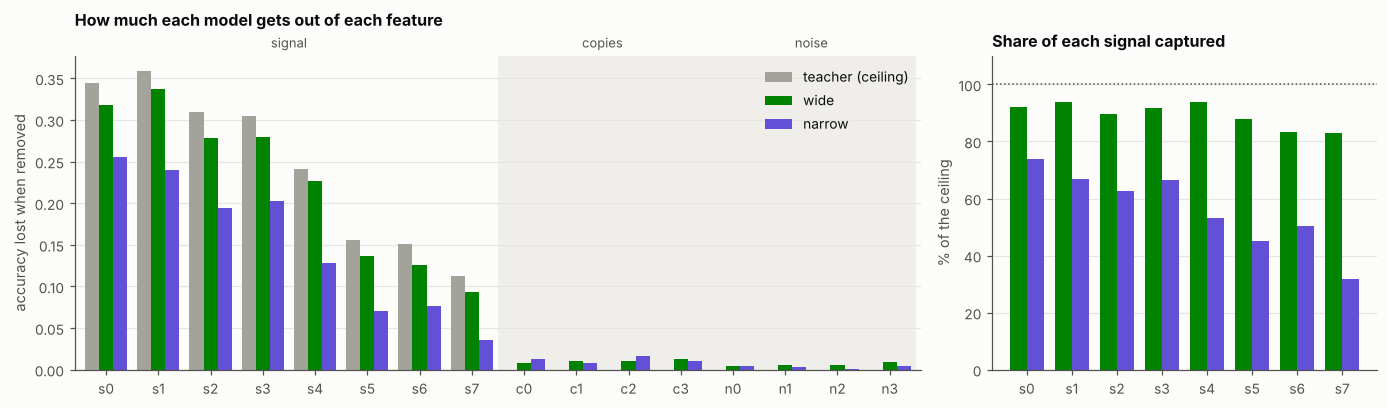

wide: captures 83–94% of each signal's information (s5–s7: 85%)
narrow: captures 32–74% of each signal's information (s5–s7: 42%)


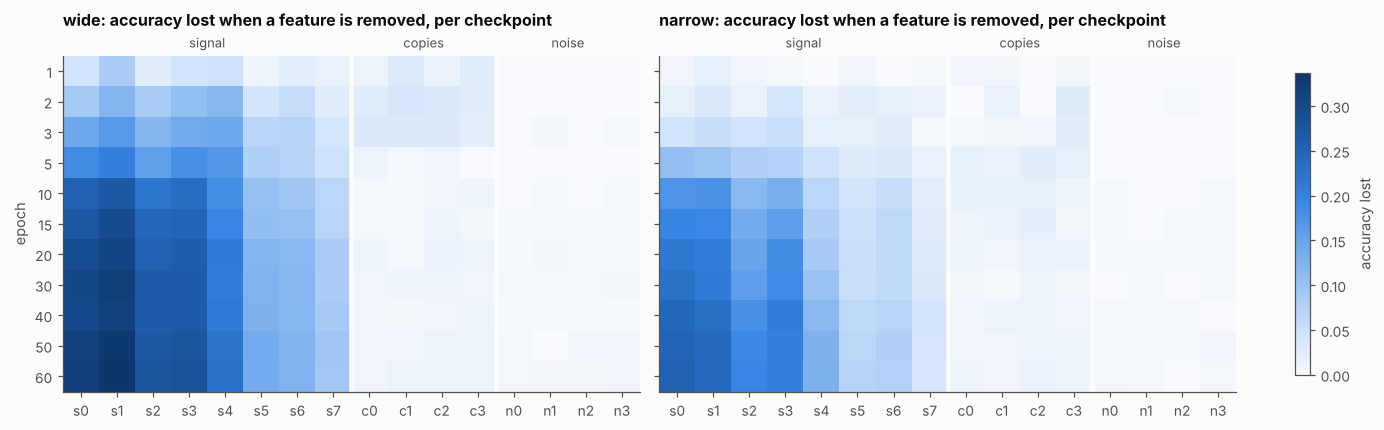

In [11]:
drop["narrow"] = accuracy_drop(NARROW)
EPOCH_SNAPSHOTS = [1, 2, 3, 5, 10, 15, 20, 30, 40, 50, 60]
t0 = time.time()
drop_by_epoch = {name: torch.stack([accuracy_drop(load(WIDTH[name], CKPTS[name][e])) for e in EPOCH_SNAPSHOTS])
                 for name in WIDTH}
print(f"{2 * len(EPOCH_SNAPSHOTS)} checkpoints in {time.time() - t0:.0f}s")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), gridspec_kw=dict(width_ratios=[2.2, 1]))
ax = axes[0]
for k, name in enumerate(["teacher (ceiling)", "wide", "narrow"]):
    ax.bar(np.arange(N_FEATURES) + (k - 1) * 0.27, drop[name].numpy(), width=0.27, label=name,
           color=MODEL_COLOR.get(name, NEUTRAL))
feature_axis(ax, group_labels=True)
ax.set_ylabel("accuracy lost when removed")
ax.legend(loc="upper right")
ax.set_title("How much each model gets out of each feature", loc="left")
ax = axes[1]
for k, name in enumerate(["wide", "narrow"]):
    captured = (drop[name][:8] / drop["teacher (ceiling)"][:8]).numpy()
    ax.bar(np.arange(8) + (k - 0.5) * 0.38, captured * 100, width=0.38, color=MODEL_COLOR[name], label=name)
ax.axhline(100, color=INK2, lw=1, ls=":")
ax.set_xticks(range(8), FEATURES[:8])
ax.grid(axis="x", visible=False)
ax.set_ylim(0, 110)
ax.set_ylabel("% of the ceiling")
ax.set_title("Share of each signal captured", loc="left")
plt.show()
for name in ["wide", "narrow"]:
    captured = (drop[name][:8] / drop["teacher (ceiling)"][:8] * 100).numpy()
    print(f"{name}: captures {captured.min():.0f}–{captured.max():.0f}% of each signal's information "
          f"(s5–s7: {captured[5:].mean():.0f}%)")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
vmax = max(v.max().item() for v in drop_by_epoch.values())
for ax, name in zip(axes, ["wide", "narrow"]):
    im = feature_heatmap(ax, drop_by_epoch[name].numpy(), [str(e) for e in EPOCH_SNAPSHOTS], vmin=0, vmax=vmax)
    ax.set_title(f"{name}: accuracy lost when a feature is removed, per checkpoint", loc="left")
axes[0].set_ylabel("epoch")
fig.colorbar(im, ax=axes, shrink=0.9, label="accuracy lost")
plt.show()

* **Capacity**: the wide model captures 83–94% of each signal's information. The narrow model captures 32–74% and
  does worst on the weak signals `s5`–`s7`: with 3 units in `fc2` it cannot carry all eight.
* **Convergence**: the wide model's rows stop changing after about epoch 30, so its use of the features has
  converged. The narrow model's rows are paler and still creep up slowly.
* In the first epochs both models lean on the copies `c0`–`c3`, then drop them as they learn the exact signals.